In [13]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [14]:
# Check missing values in each column
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Fill missing categorical values using mode
df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

# Remove rows with missing critical pickup information
df = df.dropna(subset=['pickup_zone', 'pickup_borough'])

# Check missing values after cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nUpdated Dataset Shape:")
print(df.shape)

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values Before Cleaning:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Missing Values After Cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Updated Dataset Shape:
(6407, 14)

Total Missing Values:
0


## 3. Visualizations Using Matplotlib

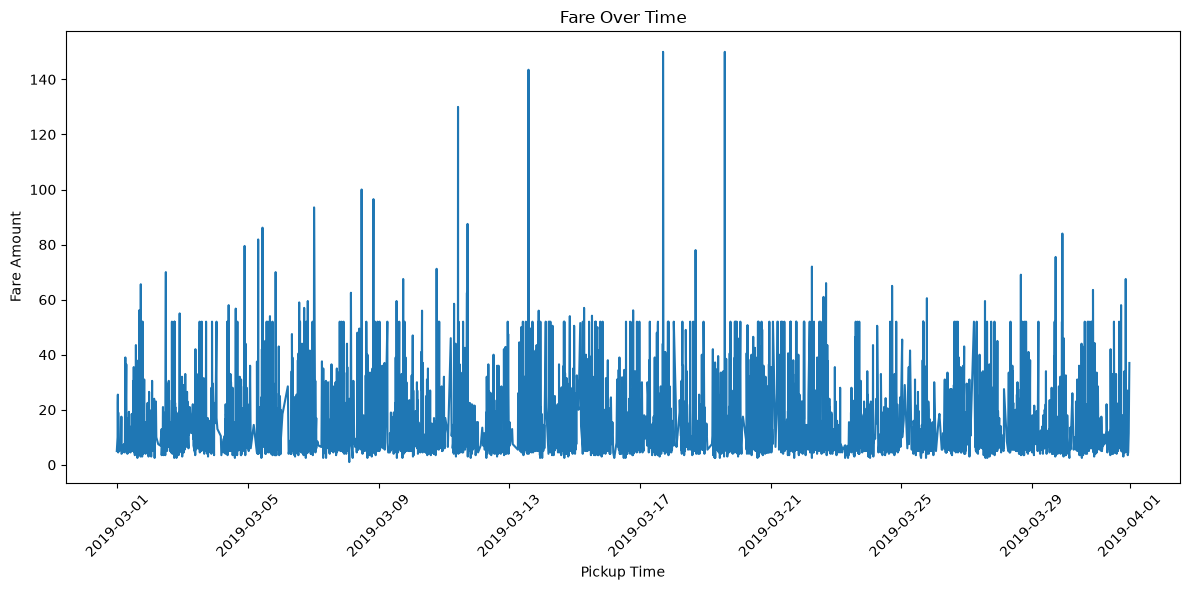

In [15]:
# Line Chart: Fare Over Time

df['pickup'] = pd.to_datetime(df['pickup'])
df = df.sort_values('pickup')

plt.figure(figsize=(12, 6))
plt.plot(df['pickup'], df['fare'])

plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

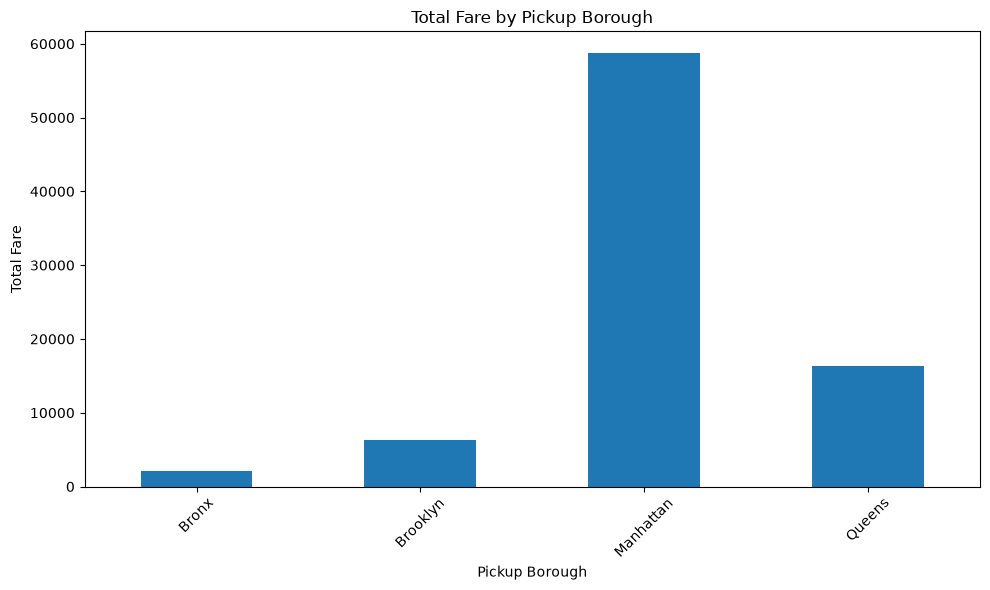

In [16]:
# Bar Chart: Total Fare by Pickup Borough

borough_fare = df.groupby('pickup_borough')['fare'].sum()

borough_fare.plot(
    kind='bar',
    figsize=(10, 6),
    title='Total Fare by Pickup Borough'
)

plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

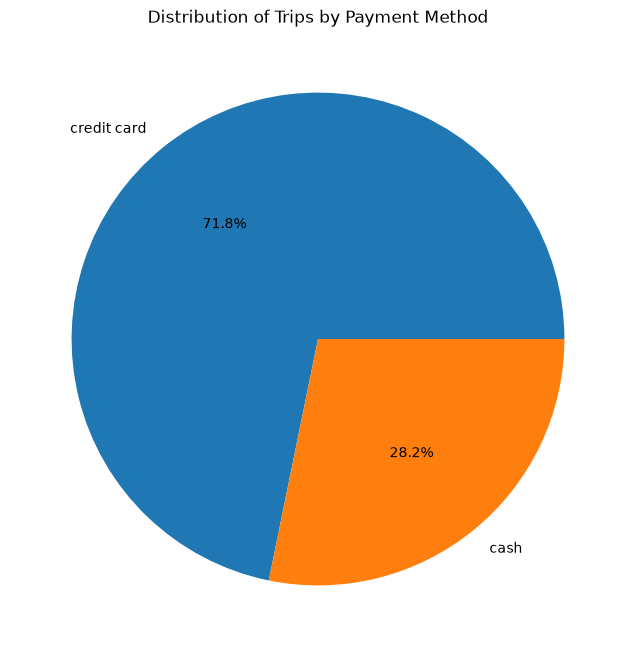

In [17]:
# Pie Chart: Distribution of Trips by Payment Method

payment_counts = df['payment'].value_counts()

payment_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(8, 8),
    title='Distribution of Trips by Payment Method'
)

plt.ylabel('')
plt.show()

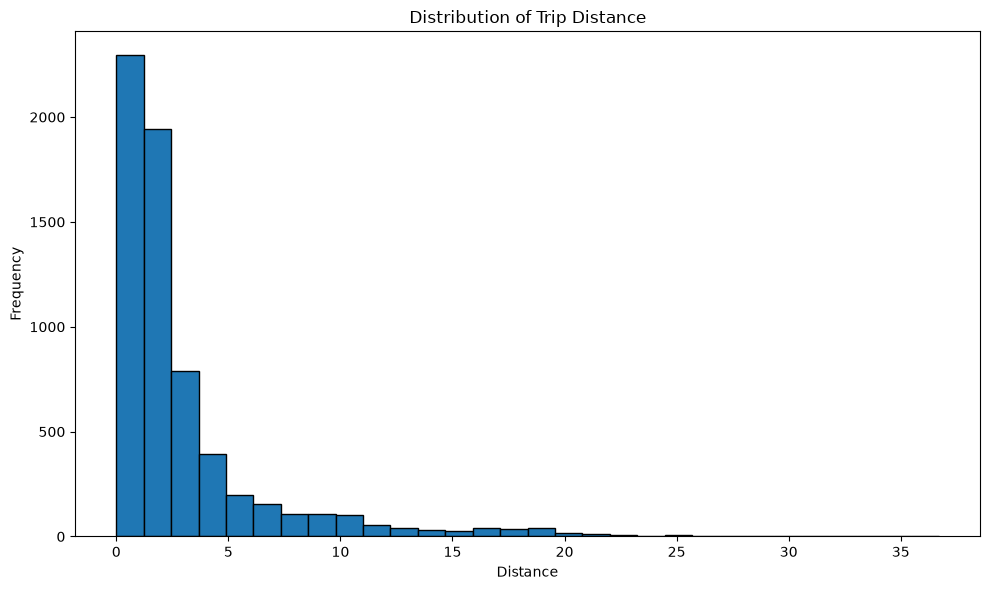

In [18]:
# Histogram: Distribution of Trip Distance

plt.figure(figsize=(10, 6))

df['distance'].plot(
    kind='hist',
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

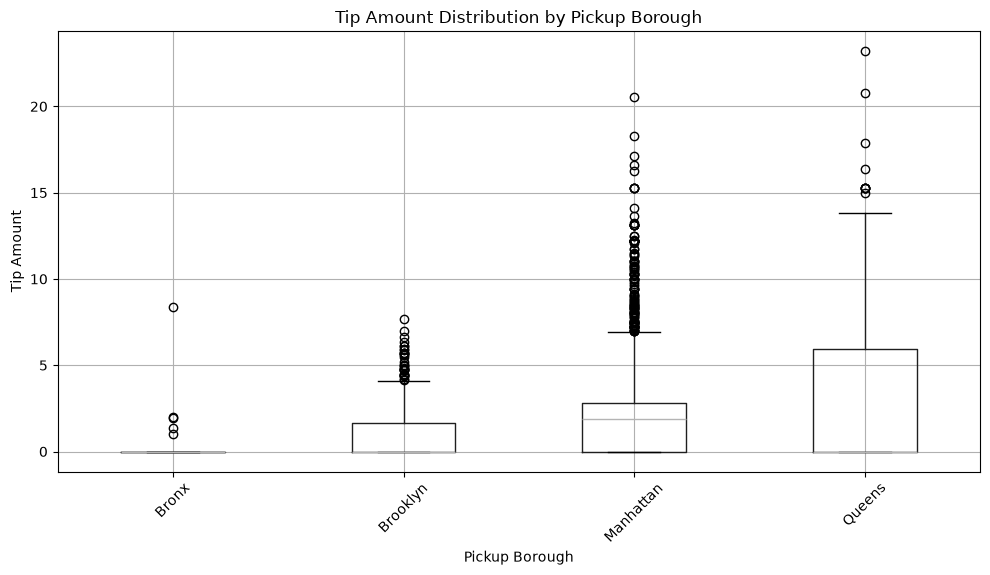

In [19]:
# Box Plot: Tip Amount Distribution by Pickup Borough

plt.figure(figsize=(10, 6))

df.boxplot(
    column='tip',
    by='pickup_borough',
    figsize=(10, 6)
)

plt.title('Tip Amount Distribution by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4. Visualizations Using Seaborn

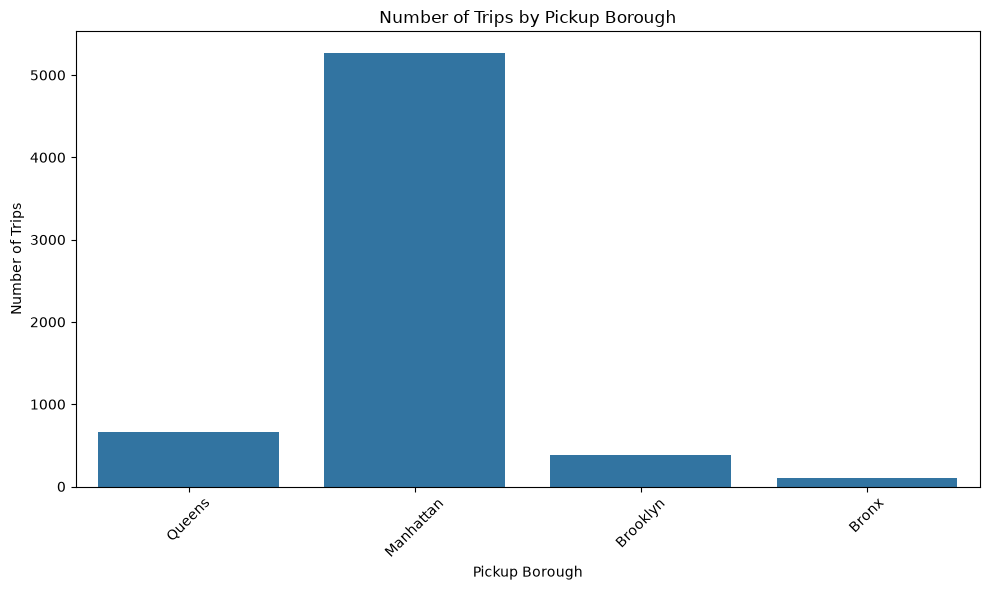

In [20]:
# Count Plot: Number of Trips by Pickup Borough

plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='pickup_borough')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

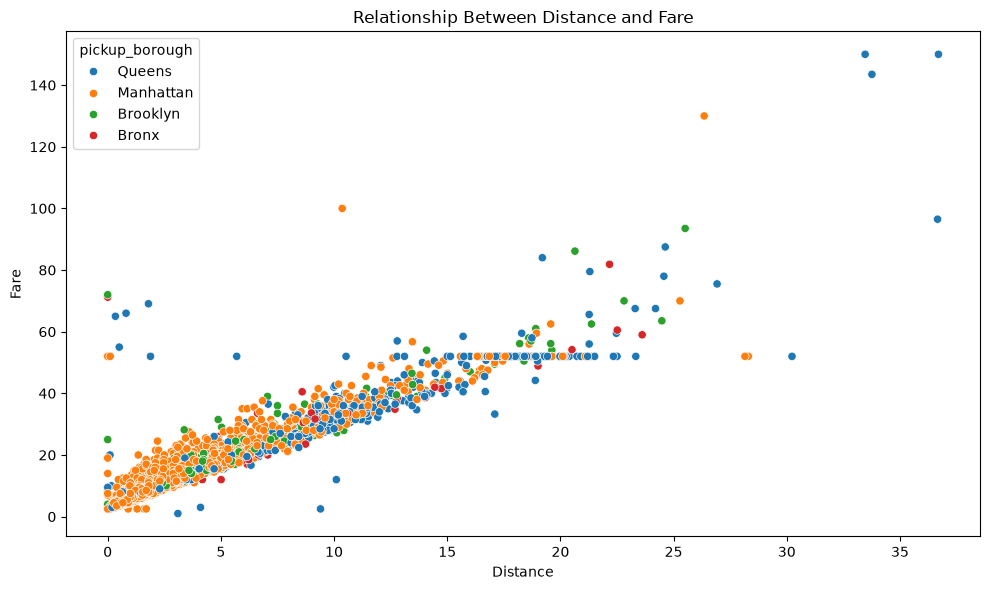

In [21]:
# Scatter Plot: Relationship Between Distance and Fare

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.title('Relationship Between Distance and Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()

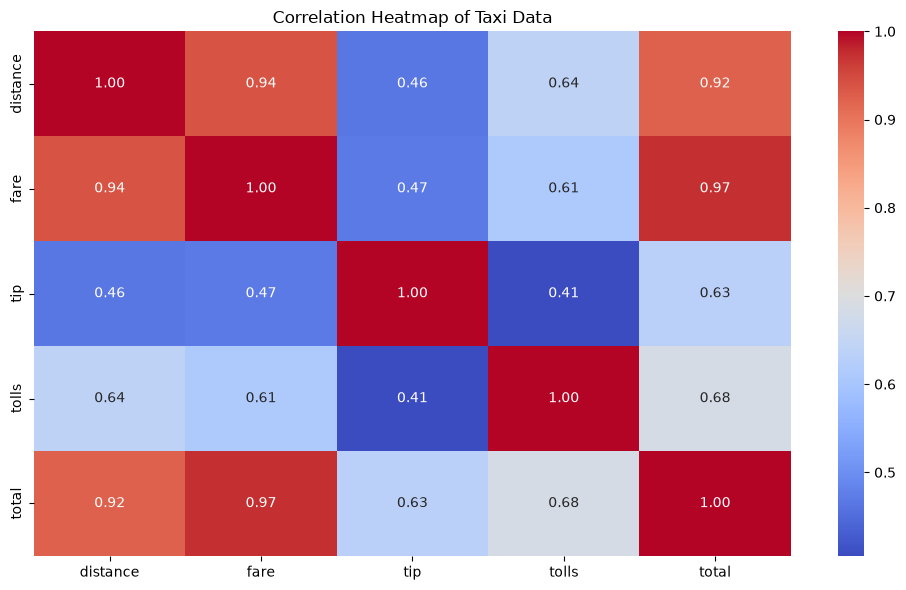

In [22]:
# Heatmap: Correlation of Numerical Variables

plt.figure(figsize=(10, 6))

numerical_data = df[['distance', 'fare', 'tip', 'tolls', 'total']]
correlation_matrix = numerical_data.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Taxi Data')
plt.tight_layout()
plt.show()

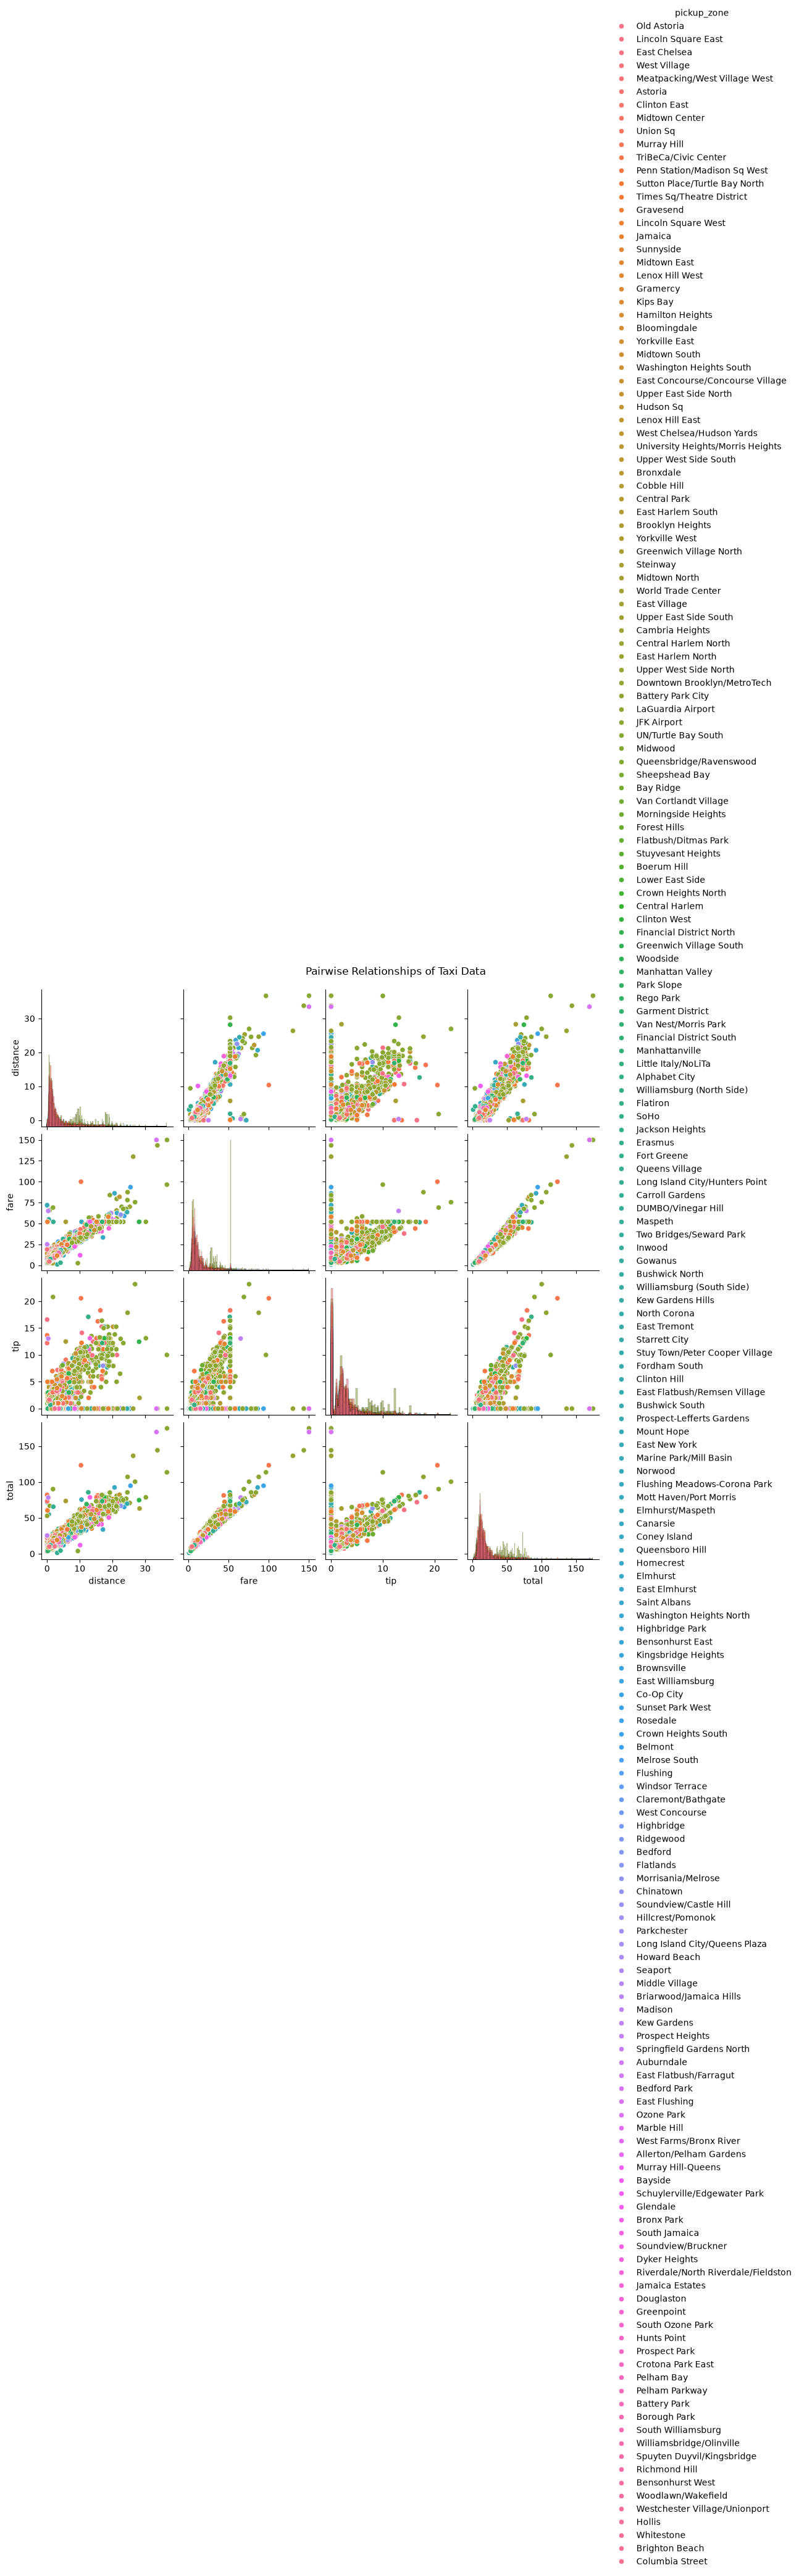

In [23]:
# Pair Plot: Relationships Between Taxi Variables

pair_data = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']]

sns.pairplot(
    pair_data,
    hue='pickup_zone',
    diag_kind='hist'
)

plt.suptitle('Pairwise Relationships of Taxi Data', y=1.02)
plt.show()

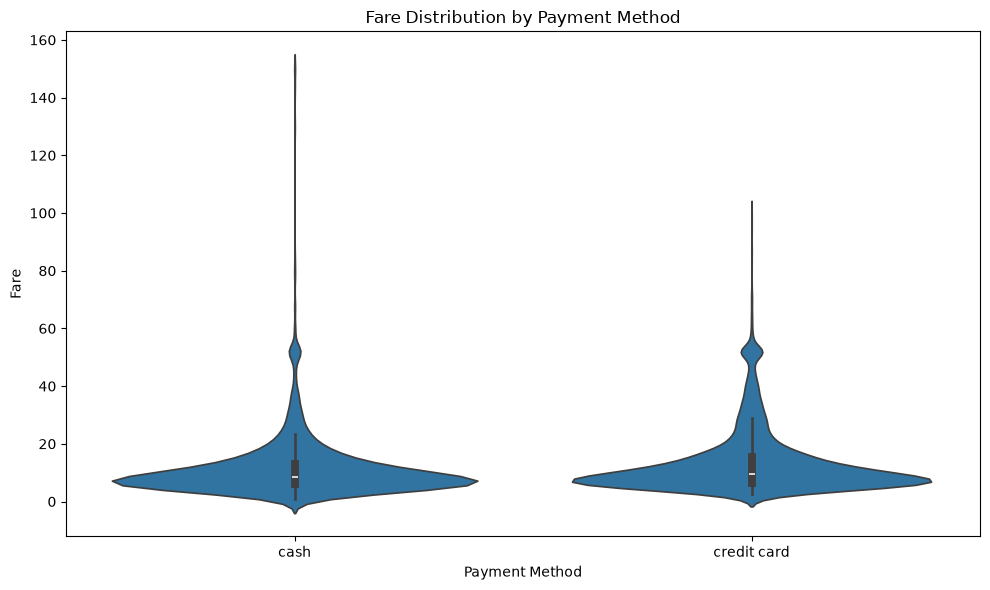

In [24]:
# Violin Plot: Fare Distribution by Payment Method

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='payment',
    y='fare'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()